<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2>
            <span style="color: #B30033;">▍</span>TRABAJO DE FIN DE MÁSTER
        </h2>
        <h1 style="margin-top: -10px;">MARCO DE TRABAJO DE RECOMENDACIÓN DE TALENTO PARA LA FORMACIÓN DE EQUIPOS EN PROYECTOS DE INGENIERÍA DEL SOFTWARE</h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;">
                    <p style="margin: 0; font-size: 1.4em; font-weight: bold;">
                        Profesores
                    </p>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="display: block; font-size: 1em; color: #D0D0D0;">
                        Aurora Vizcaíno Barceló
                    </span>
                    <span style="display: block; font-size: 1em; color: #D0D0D0; margin-top: 5px;">
                        Julio Alberto López Gómez
                    </span>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="margin-top: 30px; padding: 20px; background-color: rgba(179, 0, 51, 0.05); border-left: 4px solid #B30033; border-radius: 4px;">
    <h3 style="margin-top: 0; color: #B30033;">🎯 Objetivo de esta Libreta (Fase 4: Evaluación — contraste con las reglas expertas)</h3>
    <p style="font-size: 1.1em; line-height: 1.6; color: #E0E0E0;">
        El objetivo de esta libreta es contrastar las <strong>reglas de asociación descubiertas</strong> en la Libreta anterior contra las <strong>27 reglas definidas por la experta de dominio</strong>, con el fin de validar en qué medida los patrones encontrados en los datos coinciden, contradicen o carecen de evidencia respecto al conocimiento experto.
    </p>
    <ul style="font-size: 1.1em; line-height: 1.6; color: #D0D0D0; margin-bottom: 0;">
        <li><strong>Carga: Primero cargamos las </strong> reglas descubiertas en el documento (<code>reglas_limpias_hard.csv</code>) y reglas expertas estructuradas, las cuales he ordenado en un archivo JSON complementado información para poder hacer más fácil su tratamiento (<code>reglas_expertas_riesgo.json</code>).</li>
        <li><strong>Clasificación de alcance:</strong> de las 27 reglas expertas, solo una parte es evaluable con los datos de los que disponemos. Esto es porque el resto combina condiciones de nivel equipo/proyecto, que se evaluarán en fases posteriores del framework.</li>
        <li><strong>Contraste:</strong> para cada regla experta con componente de hard skills evaluable, buscamos la evidencia en las distintas reglas descubiertas y las clasificamos en base a si esta coincide, se contradice o si no tenemos evidencias suficientes.</li>
        <li><strong>Conclusiones:</strong> Estudiaremos la cobertura y los hallazgos relevantes para el objetivo central del proyecto.</li>
    </ul>
</div>
<br/>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Realizado por Miguel Ángel Sánchez-Medina Camacho <span style="font-size: 0.7em; font-style: italic; font-weight: normal;"></span>
        </h3>
    </div>
</div>

### 4.1. Configuración del entorno y carga de datos

En esta primera celda cargamos las reglas de asociación depuradas de la Libreta 3 (`reglas_limpias_hard.csv`, la cual ya no tienen nulos ni reglas con redundancias) y el archivo semiesctructurado con las reglas expertas (`reglas_expertas_riesgo.json`), que clasifica cada una de las 27 reglas del documento en `soft_parcial`, `hard_parcial` o `proyecto_json` según su nivel de evaluación.

In [1]:
import os
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join('../..')))
from src.hard_skills import config

reglas_limpias = pd.read_csv(config.REGLAS_LIMPIAS_PATH)
df_matriz_hard = pd.read_csv(config.MATRIZ_TRANSACCIONAL_PATH)
reglas_limpias['items_totales'] = reglas_limpias.apply(lambda row: set(str(row['antecedents']).split(' | ')) | set(str(row['consequents']).split(' | ')),axis=1)

with open(config.REGLAS_EXPERTAS_PATH, encoding='utf-8') as f:
    reglas_experto = json.load(f)['reglas']

reglas_hard = [r for r in reglas_experto if r['tipo'] == 'hard_parcial']

print(f"Reglas descubiertas en libreta 3: {len(reglas_limpias)}")
print(f"Reglas expertas totales: {len(reglas_experto)}")
print(f"Reglas expertas con componente hard evaluable: {len(reglas_hard)}")

Reglas descubiertas en libreta 3: 10107
Reglas expertas totales: 27
Reglas expertas con componente hard evaluable: 1


### 4.2. Función de Búsqueda de evidencia

Para cada las diferentes reglas expertas con componentes de hard skills evaluables, vamos a comprobar si sus ítems asociados **coexisten** en alguna regla descubierta (`reglas_limpias`). El motivo de este es saber si el algoritmo encontró esa combinación como suficientemente frecuente y fiable (soporte, confianza ≥0.6 ya aplicado en la Libreta 3).

In [2]:
def buscar_evidencia(items_esperados, df_reglas=reglas_limpias, top_n=5):
    items_esperados = set(items_esperados)
    masc = df_reglas['items_totales'].apply(lambda s: items_esperados.issubset(s))
    resultado = df_reglas[masc].sort_values('lift', ascending=False)
    return resultado.head(top_n)

### 4.3. Evaluación de la regla de cobertura tecnológica

Al llegar a este punto, vemos un problema. Como hemos observado antes, sólo contamos con una regla experta de hard skills evaluable, la #6, la cual no se puede contrastar de la misma forma que las que vimos en el pipeline de las soft skills, ya que la "cobertura tecnológica" no es un ítem fijo, es una métrica relativa al candidato (mide las tecnologías que estos dominan sobre las 80 columnas de lenguajes, BBDD, plataformas y frameworks encontrados). 

Al ser una columna calculada a posteriori, nunca puede aparecer en `reglas_limpias_hard.csv`, que solo contiene combinaciones de ítems reales extraídos por Apriori. Por ello, la regla nº 6 debe evaluarse mediante una métrica directa sobre `df_matriz_hard`, y no mediante búsqueda de evidencia en reglas minadas.

In [3]:
def columnas_tecnologicas(df_matriz):
    flags_tecnologicas = ('LanguageHaveWorkedWith_','DatabaseHaveWorkedWith_', 'PlatformHaveWorkedWith_','WebframeHaveWorkedWith_')
    columnas_tech = [c for c in df_matriz.columns if c.startswith(flags_tecnologicas)]
    return columnas_tech

def calculo_cobertura(df_matriz,columnas_tech,umbral_min=0.5):
    df_cobertura = df_matriz.copy()
    df_cobertura['cobertura'] = df_matriz[columnas_tech].sum(axis=1) / len(columnas_tech)
    df_cobertura['cobertura_tec_baja'] = (df_cobertura['cobertura'] < umbral_min).astype(int)
    return df_cobertura

def evaluacion_reglas_cobertura(r,df_cobertura,columnas_tech):
    n_total = len(df_cobertura)
    n_baja = df_cobertura['cobertura_tec_baja'].sum()
    pct_baja = n_baja / n_total
    resultado = {
        'id': r['id'],
        'riesgo': r['riesgo'],
        'n_columnas_tech_evaluadas': len(columnas_tech),
        'n_candidatos_total': n_total,
        'n_candidatos_cobertura_baja': int(n_baja),
        'pct_candidatos_cobertura_baja': round(pct_baja, 4),
        'cobertura_media_pct': round(df_cobertura['cobertura'].mean(), 4),
        'cobertura_mediana_pct': round(df_cobertura['cobertura'].median(), 4),
    }
    return resultado

columnas_tech = columnas_tecnologicas(df_matriz_hard)
print(f"Columnas tecnológicas: {len(columnas_tech)}")
df_cobertura = calculo_cobertura(df_matriz_hard, columnas_tech)

for r in reglas_hard:
    print(f"\n{'='*70}")
    print(f"Regla experta #{r['id']}: {r['riesgo']}")
    print(f"Condición: {r['condicion_texto']}")
    resultado = evaluacion_reglas_cobertura(r, df_cobertura, columnas_tech)
    print(f"→ {resultado['pct_candidatos_cobertura_baja']:.2%} de los candidatos "
          f"({resultado['n_candidatos_cobertura_baja']} de {resultado['n_candidatos_total']}) "
          f"tienen cobertura tecnológica < 50% "
          f"(cobertura media: {resultado['cobertura_media_pct']:.2%})")

Columnas tecnológicas: 80

Regla experta #6: Problema de habilidades / calidad y velocidad de desarrollo
Condición: Si el equipo carece de varias tecnologías del proyecto o la cobertura tecnológica es inferior al 50%, surgirá un problema de habilidades que afectará la calidad y velocidad de desarrollo.
→ 99.20% de los candidatos (35150 de 35434) tienen cobertura tecnológica < 50% (cobertura media: 14.20%)


A continuación, vemos de forma gráfica cómo se aplica el umbral de cobertura sobre los distintos encuestados

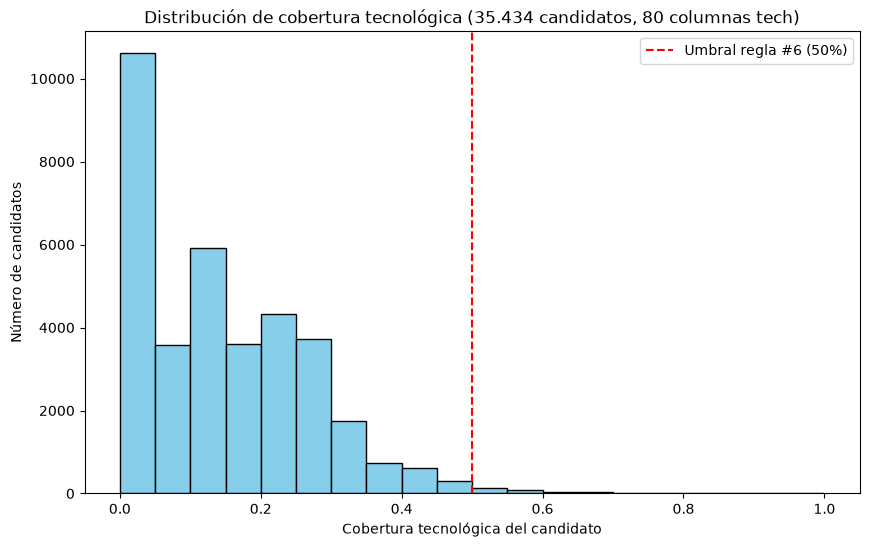

In [4]:
plt.figure(figsize=(10, 6))
plt.hist(df_cobertura['cobertura'], bins=20, color='skyblue', edgecolor='black')
plt.axvline(0.5, color='red', linestyle='--', label='Umbral regla #6 (50%)')
plt.xlabel('Cobertura tecnológica del candidato')
plt.ylabel('Número de candidatos')
plt.title('Distribución de cobertura tecnológica (35.434 candidatos, 80 columnas tech)')
plt.legend()
plt.show()

### 4.4. Conclusiones

La regla experta nº 6 es la única de la categoría `hard_parcial` aplicable a nivel de candidato individual, las 17 reglas restante son `proyecto_json` que requieren datos del proyecto (`tech_stack_required` u otros campos de `proyectos_sinteticos.json`) por lo que quedan fuera del alcance de este pipeline y esta libreta, quedando pendientes a evaluar en el motor de matching candidato-proyecto que se realizará más adelante.

El resultado que obtenemos para este proceso es que el 99,2% de los candidatos disponibles no alcanzan la cobertura tecnológica del 50%, con una cobertura media del 14,2%. Esto permite confirmar la premisa de la regla, pero con ciertos matices:

El umbral definido del 50% es exigente por su propia naturaleza: al aplicarlo sobre todas las tecnologías del dataset de forma simultánea, es muy improbable que un candidato alcance ese mínimo, lo que reduce la utilidad discriminante de la regla nº 6 para filtrar perfiles - dispara para casi cualquier candidato, en vez de distinguir a los que realmente tienen un problema de cobertura frente al resto.